# Comparing Decision Tree and K-Nearest Neighbors for Classification

## Objective
The objective of this project is to train and compare two supervised machine-learning classification algorithms, Decision Tree and K-Nearest Neighbors (KNN), using the Breast Cancer Wisconsin dataset.

The models are evaluated using accuracy, precision, recall, F1-score and confusion matrices.

## Dataset Overview

This project uses the Breast Cancer Wisconsin dataset available through scikit-learn.

- Number of samples: 569
- Number of numerical features: 30
- Target classes: Malignant and Benign
- Problem type: Binary classification

The features contain numerical measurements of cell nuclei. The target variable indicates the corresponding class.

## Methodology

1. Load the dataset using scikit-learn.
2. Split the data into training and testing sets using an 80:20 ratio.
3. Standardise the features for KNN because it relies on distance calculations.
4. Train a Decision Tree classifier on the original features.
5. Train a KNN classifier using the scaled features.
6. Evaluate both models on the same test set.
7. Compare accuracy, precision, recall, F1-score and confusion matrices.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load the dataset
dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

print("Dataset shape:", X.shape)
print("Target classes:", dataset.target_names)

X.head()

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 455
Testing samples: 114


In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling complete!")

Feature scaling complete!


In [18]:
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

dt_predictions = dt_model.predict(X_test)

print("Decision Tree accuracy:",
      accuracy_score(y_test, dt_predictions))

Decision Tree accuracy: 0.9473684210526315


In [19]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_predictions = knn_model.predict(X_test_scaled)

print("KNN accuracy:",
      accuracy_score(y_test, knn_predictions))

KNN accuracy: 0.9473684210526315


In [20]:
print("Decision Tree Confusion Matrix:")
print(confusion_matrix(y_test, dt_predictions))

print("\nKNN Confusion Matrix:")
print(confusion_matrix(y_test, knn_predictions))

Decision Tree Confusion Matrix:
[[40  3]
 [ 3 68]]

KNN Confusion Matrix:
[[40  3]
 [ 3 68]]


           Model  Accuracy
0  Decision Tree  0.947368
1            KNN  0.947368


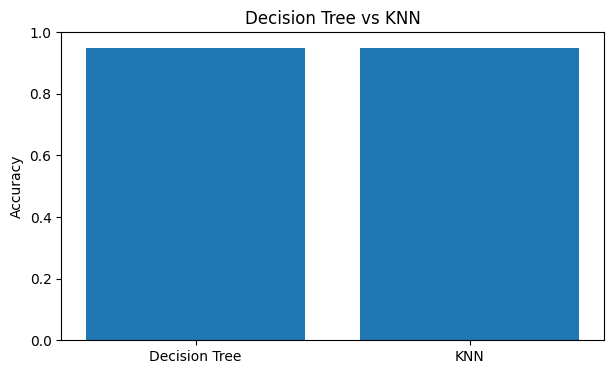

In [21]:
# Compare model accuracy
dt_accuracy = accuracy_score(y_test, dt_predictions)
knn_accuracy = accuracy_score(y_test, knn_predictions)

results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN"],
    "Accuracy": [dt_accuracy, knn_accuracy]
})

print(results)

# Plot the comparison
plt.figure(figsize=(7, 4))
plt.bar(results["Model"], results["Accuracy"])
plt.ylabel("Accuracy")
plt.title("Decision Tree vs KNN")
plt.ylim(0, 1)
plt.show()

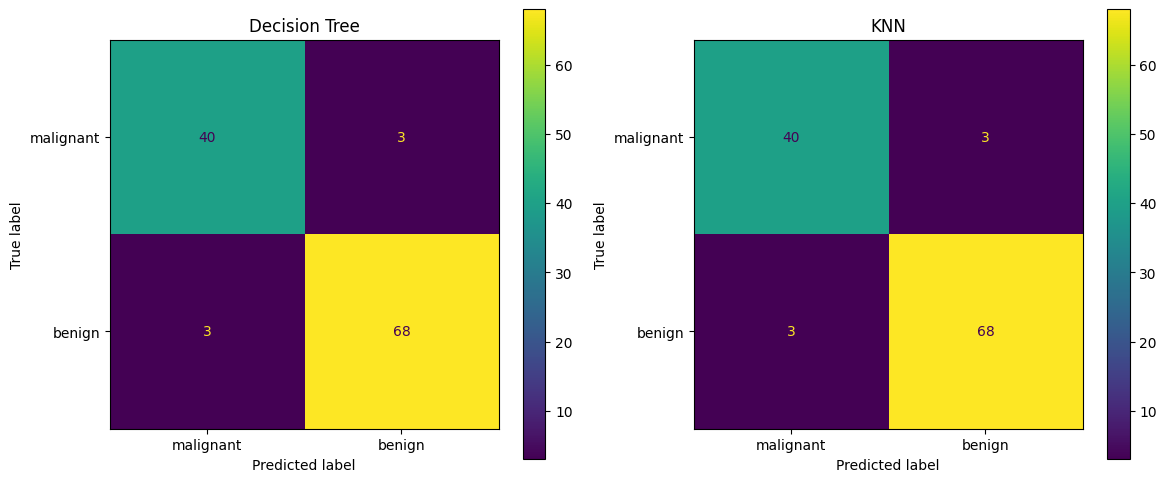

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, dt_predictions,
    display_labels=dataset.target_names,
    ax=axes[0]
)
axes[0].set_title("Decision Tree")

ConfusionMatrixDisplay.from_predictions(
    y_test, knn_predictions,
    display_labels=dataset.target_names,
    ax=axes[1]
)
axes[1].set_title("KNN")

plt.tight_layout()
plt.show()

In [23]:
print("DECISION TREE")
print(classification_report(
    y_test, dt_predictions,
    target_names=dataset.target_names
))

print("KNN")
print(classification_report(
    y_test, knn_predictions,
    target_names=dataset.target_names
))

DECISION TREE
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        43
      benign       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114

KNN
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        43
      benign       0.96      0.96      0.96        71

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



In [24]:
import numpy as np

print("Decision Tree accuracy:", accuracy_score(y_test, dt_predictions))
print("KNN accuracy:", accuracy_score(y_test, knn_predictions))

print("\nAre all predictions identical?")
print(np.array_equal(dt_predictions, knn_predictions))

print("\nNumber of test samples predicted differently:")
print(np.sum(dt_predictions != knn_predictions))

print("\nDecision Tree confusion matrix:")
print(confusion_matrix(y_test, dt_predictions))

print("\nKNN confusion matrix:")
print(confusion_matrix(y_test, knn_predictions))

Decision Tree accuracy: 0.9473684210526315
KNN accuracy: 0.9473684210526315

Are all predictions identical?
False

Number of test samples predicted differently:
6

Decision Tree confusion matrix:
[[40  3]
 [ 3 68]]

KNN confusion matrix:
[[40  3]
 [ 3 68]]


In [25]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (weighted)",
               "Recall (weighted)", "F1-score (weighted)"],

    "Decision Tree": [
        accuracy_score(y_test, dt_predictions),
        *[
            classification_report(
                y_test, dt_predictions, output_dict=True
            )["weighted avg"][m]
            for m in ["precision", "recall", "f1-score"]
        ]
    ],

    "KNN": [
        accuracy_score(y_test, knn_predictions),
        *[
            classification_report(
                y_test, knn_predictions, output_dict=True
            )["weighted avg"][m]
            for m in ["precision", "recall", "f1-score"]
        ]
    ]
})

print(comparison.round(4).to_string(index=False))


              Metric  Decision Tree    KNN
            Accuracy         0.9474 0.9474
Precision (weighted)         0.9474 0.9474
   Recall (weighted)         0.9474 0.9474
 F1-score (weighted)         0.9474 0.9474


In [26]:
print("DECISION TREE — Per-class results")
print(classification_report(
    y_test, dt_predictions,
    target_names=dataset.target_names,
    digits=4
))

print("KNN — Per-class results")
print(classification_report(
    y_test, knn_predictions,
    target_names=dataset.target_names,
    digits=4
))

print("Decision Tree confusion matrix:")
print(confusion_matrix(y_test, dt_predictions))

print("KNN confusion matrix:")
print(confusion_matrix(y_test, knn_predictions))


DECISION TREE — Per-class results
              precision    recall  f1-score   support

   malignant     0.9302    0.9302    0.9302        43
      benign     0.9577    0.9577    0.9577        71

    accuracy                         0.9474       114
   macro avg     0.9440    0.9440    0.9440       114
weighted avg     0.9474    0.9474    0.9474       114

KNN — Per-class results
              precision    recall  f1-score   support

   malignant     0.9302    0.9302    0.9302        43
      benign     0.9577    0.9577    0.9577        71

    accuracy                         0.9474       114
   macro avg     0.9440    0.9440    0.9440       114
weighted avg     0.9474    0.9474    0.9474       114

Decision Tree confusion matrix:
[[40  3]
 [ 3 68]]
KNN confusion matrix:
[[40  3]
 [ 3 68]]


In [27]:
# Find test samples where the models disagree
differences = np.where(dt_predictions != knn_predictions)[0]

print("Number of disagreements:", len(differences))

for i in differences[:10]:
    print(
        "Test sample:", i,
        "| Actual:", dataset.target_names[y_test.iloc[i]],
        "| Decision Tree:", dataset.target_names[dt_predictions[i]],
        "| KNN:", dataset.target_names[knn_predictions[i]]
    )

Number of disagreements: 6
Test sample: 13 | Actual: malignant | Decision Tree: malignant | KNN: benign
Test sample: 46 | Actual: benign | Decision Tree: malignant | KNN: benign
Test sample: 52 | Actual: benign | Decision Tree: benign | KNN: malignant
Test sample: 82 | Actual: malignant | Decision Tree: benign | KNN: malignant
Test sample: 91 | Actual: benign | Decision Tree: benign | KNN: malignant
Test sample: 108 | Actual: benign | Decision Tree: malignant | KNN: benign


## Results and Discussion

- Both Decision Tree and KNN achieved **94.74% accuracy**.
- Correct predictions: 108 out of 114 test samples for each model.
- Both models produced identical confusion matrices:
  - True negatives: 40
  - False positives: 3
  - False negatives: 3
  - True positives: 68
- Both models achieved identical precision, recall and F1-scores for each class.
- The models disagreed on 6 individual test samples, with each model correct on 3 and incorrect on 3 of those samples.
- Identical overall metrics do not mean the models make identical predictions.
- Cross-validation could help determine whether the similar performance remains consistent across different data splits.

## Limitations

- The comparison uses a single train/test split, so the results may vary with different splits.
- Only two classification algorithms are compared.
- Model performance on this dataset does not establish suitability for real-world medical diagnosis.
- Cross-validation and further hyperparameter tuning could provide a more robust comparison.

## Conclusion

- Compared Decision Tree and K-Nearest Neighbors (KNN) using the Breast Cancer Wisconsin dataset.
- Both models achieved **94.74% test accuracy** on the selected test split.
- Neither model outperformed the other according to the measured aggregate metrics.
- The models made different predictions for 6 test samples despite having identical overall scores.
- Further work could include cross-validation, hyperparameter tuning and testing additional classification algorithms.
- This project is for educational purposes and is not intended for medical diagnosis.